In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys

sys.path.append("../..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import xarray as xr

from src.results.plotting import (
    plot_gmst_anomalies,
    plot_gmst_anomalies_subset_vs_all
)


sns.set_style("whitegrid", {"grid.color": ".93"})

In [3]:
paths = json.load(open("../../paths_so4.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_temporary = Path(paths["path_data_temporary"])
path_data_gcm = Path("/net/atmos/data/cmip5-ng/")

path_figs = Path("../../figs")
(path_figs / "driving_gcms").mkdir(parents=True, exist_ok=True)

# Load GCM data

In [5]:
gcms = ["CNRM-CM5_r1i1p1", "HadGEM2-ES_r1i1p1", "NorESM1-M_r1i1p1", "MPI-ESM-LR_r1i1p1", "EC-EARTH_r12i1p1"]
ensemble_members = [gcm.split("_")[-1] for gcm in gcms]
gcms = [gcm.split("_")[0] for gcm in gcms]

In [6]:
var = "tas"
temp_res = "ann"
scenarios = ["rcp26", "rcp45", "rcp85"]

subset_gcms = []
for gcm, ens in zip(gcms, ensemble_members):
    for scenario in scenarios:
        subset_gcms.extend(sorted(path_data_gcm.glob(f"{var}/*{temp_res}_{gcm}_{scenario}_*{ens}*_g025.nc")))

len(subset_gcms)

15

In [7]:
all_other_gcms_data = []
for scenario in scenarios:
    all_other_gcms_data.extend(
        sorted(path_data_gcm.glob(f"{var}/*{temp_res}*{scenario}_*_g025.nc"))
    )
# Remove all elements in matches from all_other_gcms_data
all_other_gcms_data = [item for item in all_other_gcms_data if item not in subset_gcms]
len(all_other_gcms_data)

251

# Plot

In [13]:
reference_period = slice("1871", "1900")

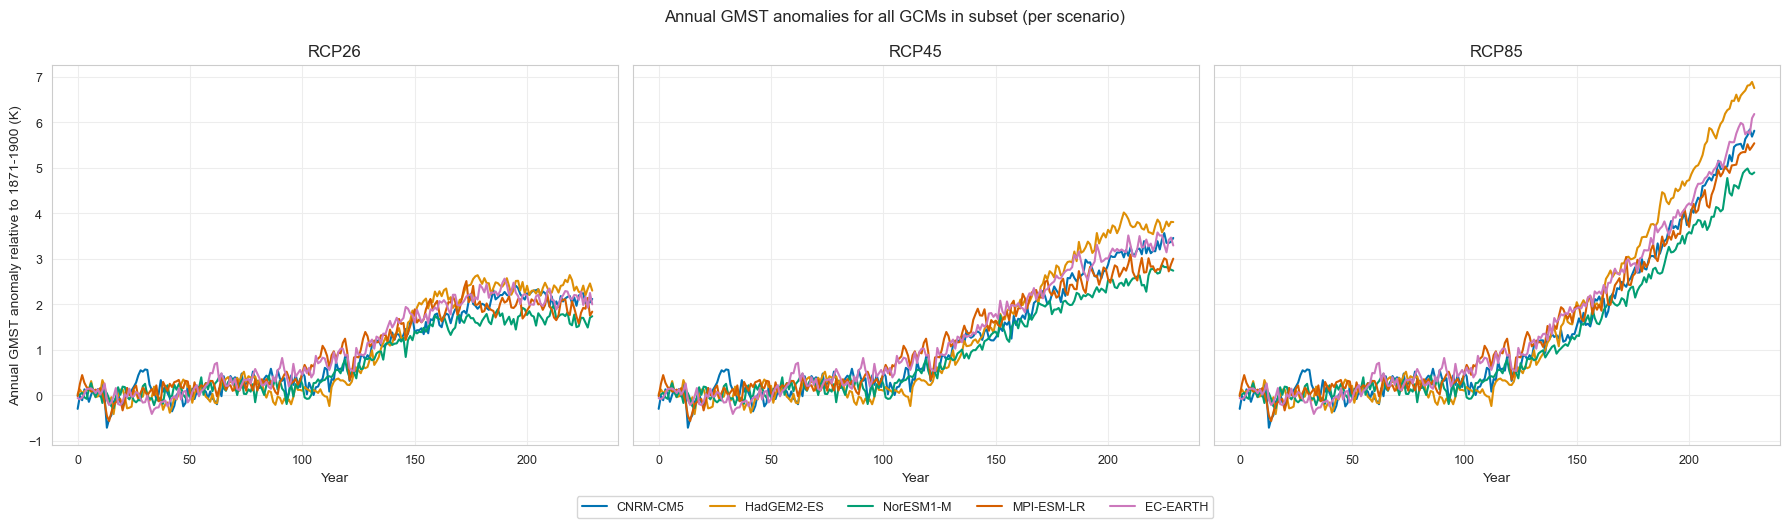

In [39]:
plot_gmst_anomalies(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    var=var,
    reference_period=reference_period,
    time_dim="time",
    figsize=(18, 5),
    path_savefig=path_figs / "driving_gcms" / "annual_gmst_subset_anomalies.png"
)

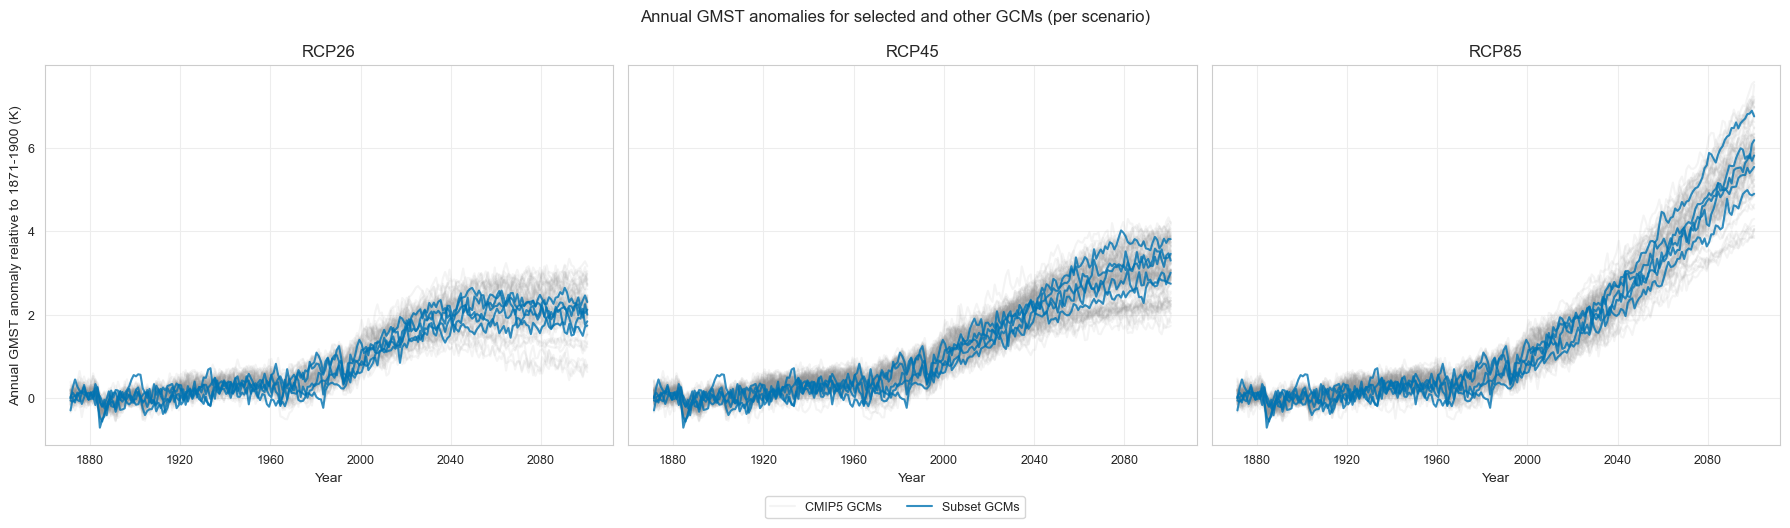

In [42]:
plot_gmst_anomalies_subset_vs_all(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    all_other_gcms_data=all_other_gcms_data,
    var=var,
    reference_period=reference_period,
    time_dim="year",
    figsize=(18, 5),
    # path_savefig=path_figs / "driving_gcms" / "annual_gmst_all_gcms_anomalies_individual_subset.png"
    separate_subset=False
)

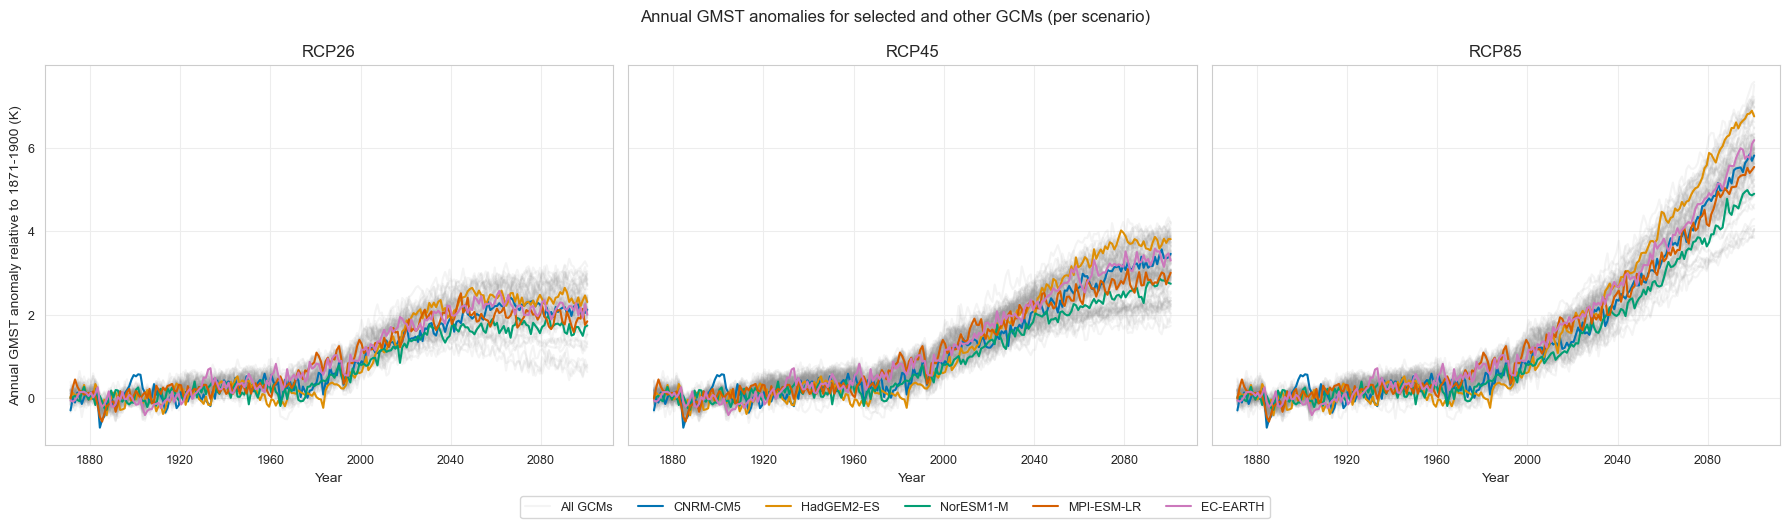

In [45]:
plot_gmst_anomalies_subset_vs_all(
    scenarios=scenarios,
    subset_gcms=subset_gcms,
    all_other_gcms_data=all_other_gcms_data,
    var=var,
    reference_period=reference_period,
    time_dim="year",
    figsize=(18, 5),
    path_savefig=path_figs / "driving_gcms" / "annual_gmst_all_gcms_anomalies_individual_subset.png",
    separate_subset=True
)